In [2]:
import mat4py
import numpy as np
import pandas as pd
import lanelet2
from pyproj import Proj, transform

In [24]:
from pyproj import Geod

geod = Geod(ellps="WGS84")

In [50]:
def add_offset_path_smooth(df, offset_meters=1.0, smoothing_window=10, min_move_dist=0.05):
    """
    smoothing_window: Number of points to average to determine the heading.
                      Higher = smoother path, but cuts corners slightly.
                      Lower = more responsive, but jittery (fuzzy).
    min_move_dist:    Ignore movements smaller than this (in meters) to prevent 
                      noise when stationary.
    """
    df = df.copy()
    R = 6378137.0  # Earth radius
    
    # 1. Convert to radians
    lats = np.radians(df['lat'].values)
    lons = np.radians(df['lon'].values)
    
    # 2. Calculate raw local movements (dx, dy)
    dlat = np.diff(lats)
    dlon = np.diff(lons)
    
    raw_dy = dlat * R
    raw_dx = dlon * R * np.cos(lats[:-1])
    
    # Pad to match length (repeat last delta)
    raw_dy = np.append(raw_dy, raw_dy[-1])
    raw_dx = np.append(raw_dx, raw_dx[-1])
    
    # 3. SMOOTHING: Average the direction vectors (dx, dy)
    # This removes the "jitter" by looking at the trend over 'smoothing_window' points
    dx_series = pd.Series(raw_dx)
    dy_series = pd.Series(raw_dy)
    
    # center=True looks at past and future points (great for post-processing)
    dx_smooth = dx_series.rolling(window=smoothing_window, center=True, min_periods=1).mean().values
    dy_smooth = dy_series.rolling(window=smoothing_window, center=True, min_periods=1).mean().values
    
    # 4. Calculate Heading from SMOOTHED vectors
    headings = np.arctan2(dy_smooth, dx_smooth)
    
    # 5. Lock Heading if stationary (Filtering)
    # Calculate magnitude of the smoothed movement
    smooth_dist = np.sqrt(dx_smooth**2 + dy_smooth**2)
    
    # If movement is tiny, replace heading with NaN, then fill with last known heading
    headings_series = pd.Series(headings)
    headings_series[smooth_dist < min_move_dist] = np.nan
    headings_series = headings_series.ffill().bfill() # Forward fill, then back fill start
    
    clean_headings = headings_series.values
    
    # 6. Calculate Offset (Right = -90 degrees)
    offset_headings = clean_headings - np.pi/2
    
    offset_dx = offset_meters * np.cos(offset_headings)
    offset_dy = offset_meters * np.sin(offset_headings)
    
    # 7. Apply Offset to original Lat/Lon
    delta_lat = (offset_dy / R) * (180 / np.pi)
    delta_lon = (offset_dx / (R * np.cos(lats))) * (180 / np.pi)
    
    df['lat_offset'] = df['lat'] + delta_lat
    df['lon_offset'] = df['lon'] + delta_lon
    
    return df

In [84]:
# read matlab file
data = mat4py.loadmat('campus.mat')

In [88]:
path = pd.read_csv("utm.csv",header=None)

In [56]:
path = add_offset_path(path)

In [89]:
path

,0,1,2,3,4,5,6,7,8,9,...,79,80,81,82,83,84,85,86,87,88
0,1764770876,864084234,odom,base_link,360605.484158,5.258698e+06,167.322510,-0.012569,0.004563,-0.861526,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1764770876,873919906,odom,base_link,360605.484158,5.258698e+06,167.322510,-0.012569,0.004563,-0.861526,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1764770876,885967356,odom,base_link,360605.484085,5.258698e+06,167.322435,-0.012564,0.004564,-0.861525,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1764770876,893214099,odom,base_link,360605.484085,5.258698e+06,167.322435,-0.012564,0.004564,-0.861525,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1764770876,911667658,odom,base_link,360605.484042,5.258698e+06,167.322363,-0.012575,0.004556,-0.861526,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5293,1764770929,793004289,odom,base_link,360604.488002,5.258697e+06,168.277677,-0.012220,0.003620,-0.863868,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5294,1764770929,814832126,odom,base_link,360604.488002,5.258697e+06,168.277677,-0.012251,0.003607,-0.863866,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5295,1764770929,817821115,odom,base_link,360604.488002,5.258697e+06,168.277677,-0.012251,0.003607,-0.863866,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5296,1764770929,824779310,odom,base_link,360604.488685,5.258697e+06,168.277781,-0.012280,0.003588,-0.863864,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [74]:
# 1. Setup your columns (Based on your image)
# Column 4 = Easting, Column 5 = Northing
x_col = 4
y_col = 5

# 2. Define your offset settings
distance = 1.0       # 1 meter
bearing_deg = 90     # 45 degrees (North-East). Change to 90 for East, 0 for North.

# 3. Calculate the shift (Vector math)
theta = np.radians(bearing_deg)
delta_x = np.sin(theta) * distance
delta_y = np.cos(theta) * distance

# 4. Apply to the DataFrame
# We use .iloc because your columns are indexed by number (0, 1, 2...)
path['easting_shifted'] = path.iloc[:, 4] + delta_x
path['northing_shifted'] = path.iloc[:, 5] + delta_y

In [90]:
# 1. Setup Data
# Copy to avoid SettingWithCopy warnings
clean_path = path.copy()
x_col = 4
y_col = 5

# 2. FILTER: Remove stationary points
# Calculate distance to the next point
# We use .diff() to check the change from row to row
dx_raw = clean_path.iloc[:, x_col].diff()
dy_raw = clean_path.iloc[:, y_col].diff()
dist = np.sqrt(dx_raw**2 + dy_raw**2)

# Keep only points where the robot moved more than 1 cm (0.01m)
# This removes the "duplicate" rows shown in your screenshot
clean_path = clean_path[dist > 0.01].reset_index(drop=True)

# 3. SMOOTHING (Optional but recommended)
# This smooths out GPS jitter to make the rails parallel and clean
# A window of 5-10 usually works well for high-freq data
window_size = 5
clean_path['x_smooth'] = clean_path.iloc[:, x_col].rolling(window=window_size, center=True).mean()
clean_path['y_smooth'] = clean_path.iloc[:, y_col].rolling(window=window_size, center=True).mean()

# Fill NaN values created by rolling window with original values
clean_path['x_smooth'] = clean_path['x_smooth'].fillna(clean_path.iloc[:, x_col])
clean_path['y_smooth'] = clean_path['y_smooth'].fillna(clean_path.iloc[:, y_col])

# 4. CALCULATE OFFSET (Using Smoothed Data)
x = clean_path['x_smooth'].values
y = clean_path['y_smooth'].values

# Calculate Gradient (Direction)
dx = np.gradient(x)
dy = np.gradient(y)

# Calculate Normal Vector (Left/Right)
perp_x = -dy
perp_y = dx

# Normalize
magnitude = np.sqrt(perp_x**2 + perp_y**2) + 1e-6
ux = perp_x / magnitude
uy = perp_y / magnitude

# Apply 1m Offset
offset = 1.0

clean_path['left_easting'] = x + (ux * offset)
clean_path['left_northing'] = y + (uy * offset)
clean_path['right_easting'] = x - (ux * offset)
clean_path['right_northing'] = y - (uy * offset)

In [83]:
path

,0,1,2,3,4,5,6,7,8,9,...,83,84,85,86,87,88,left_easting,left_northing,right_easting,right_northing
0,1764770876,864084234,odom,base_link,360605.484158,5.258698e+06,167.322510,-0.012569,0.004563,-0.861526,...,0.0,0.0,0.0,0.0,0.0,0.0,360605.484158,5.258698e+06,360605.484158,5.258698e+06
1,1764770876,873919906,odom,base_link,360605.484158,5.258698e+06,167.322510,-0.012569,0.004563,-0.861526,...,0.0,0.0,0.0,0.0,0.0,0.0,360606.209759,5.258697e+06,360604.758556,5.258698e+06
2,1764770876,885967356,odom,base_link,360605.484085,5.258698e+06,167.322435,-0.012564,0.004564,-0.861525,...,0.0,0.0,0.0,0.0,0.0,0.0,360606.209687,5.258697e+06,360604.758483,5.258698e+06
3,1764770876,893214099,odom,base_link,360605.484085,5.258698e+06,167.322435,-0.012564,0.004564,-0.861525,...,0.0,0.0,0.0,0.0,0.0,0.0,360606.246885,5.258697e+06,360604.721286,5.258698e+06
4,1764770876,911667658,odom,base_link,360605.484042,5.258698e+06,167.322363,-0.012575,0.004556,-0.861526,...,0.0,0.0,0.0,0.0,0.0,0.0,360606.246841,5.258697e+06,360604.721242,5.258698e+06
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5293,1764770929,793004289,odom,base_link,360604.488002,5.258697e+06,168.277677,-0.012220,0.003620,-0.863868,...,0.0,0.0,0.0,0.0,0.0,0.0,360604.488002,5.258697e+06,360604.488002,5.258697e+06
5294,1764770929,814832126,odom,base_link,360604.488002,5.258697e+06,168.277677,-0.012251,0.003607,-0.863866,...,0.0,0.0,0.0,0.0,0.0,0.0,360604.488002,5.258697e+06,360604.488002,5.258697e+06
5295,1764770929,817821115,odom,base_link,360604.488002,5.258697e+06,168.277677,-0.012251,0.003607,-0.863866,...,0.0,0.0,0.0,0.0,0.0,0.0,360604.528300,5.258698e+06,360604.447703,5.258696e+06
5296,1764770929,824779310,odom,base_link,360604.488685,5.258697e+06,168.277781,-0.012280,0.003588,-0.863864,...,0.0,0.0,0.0,0.0,0.0,0.0,360604.528984,5.258698e+06,360604.448387,5.258696e+06


In [85]:
def diff_to (x1, y1, x2, y2):
    return np.sqrt((x2 - x1)**2 + (y2 - y1)**2)

In [86]:
left_line = data['referenceDataToPlot'][0]['finalPath']
right_line = data['referenceDataToPlot'][1]['finalPath']

In [87]:
left_line = left_line[200:1500]
right_line = right_line[210:1700]

In [88]:
x_left = []
y_left = []
for x in left_line:
    x_left.append(x[0])
for y in left_line:
    y_left.append(y[1])

In [89]:
x_right = []
y_right = []
for x in right_line:
    x_right.append(x[0])
for y in right_line:
    y_right.append(y[1])

In [56]:
lanes = []

for i in range(len(data["lanelets"])):
    path = np.array(data["lanelets"][i]["centerLine"])
    leftLane = np.array([])
    rightLane = np.array([])
    end_coord = path[-1]
    left_index = 0
    right_index = 0
    for line in data["lanelets"][i]["leftLine"]:
        if diff_to(line[0],line[1],end_coord[0],end_coord[1]) < 2.0:
            break
        left_index += 1
    for line in data["lanelets"][i]["rightLine"]:
        if diff_to(line[0],line[1],end_coord[0],end_coord[1]) < 2.0:
            break
        right_index += 1
    leftLane = np.array(data["lanelets"][i]["leftLine"][:left_index])
    rightLane = np.array(data["lanelets"][i]["rightLine"][:right_index])

    lanes.append([path,leftLane,rightLane])

In [57]:
import numpy as np
from pyproj import Proj, Transformer

# Define the UTM and WGS84 projections
utm = Proj(proj='utm', zone=33, ellps='WGS84')  # Adjust the zone as needed
wgs84 = Proj(proj='latlong', datum='WGS84')  # WGS84 coordinate system

# Create a transformer object
transformer = Transformer.from_proj(utm, wgs84)

def convert_to_wgs84(utm_coords):
    return np.array([transformer.transform(x, y) for x, y in utm_coords])

lanes = []

for i in range(len(data["lanelets"])):
    path = np.array(data["lanelets"][i]["centerLine"])
    leftLane = np.array([])
    rightLane = np.array([])
    end_coord = path[-1]
    left_index = 0
    right_index = 0
    for line in data["lanelets"][i]["leftLine"]:
        if diff_to(line[0], line[1], end_coord[0], end_coord[1]) < 2.0:
            break
        left_index += 1
    for line in data["lanelets"][i]["rightLine"]:
        if diff_to(line[0], line[1], end_coord[0], end_coord[1]) < 2.0:
            break
        right_index += 1
    leftLane = np.array(data["lanelets"][i]["leftLine"][:left_index])
    rightLane = np.array(data["lanelets"][i]["rightLine"][:right_index])

    # Convert UTM coordinates to WGS84
    path_wgs84 = convert_to_wgs84(path)
    leftLane_wgs84 = convert_to_wgs84(leftLane)
    rightLane_wgs84 = convert_to_wgs84(rightLane)

    lanes.append([path, leftLane, rightLane])

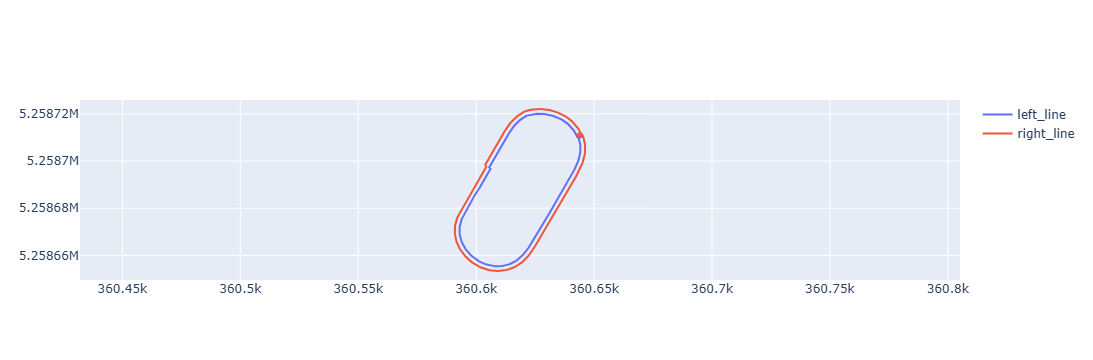

In [93]:
#plot lane1 using plotly
import plotly.graph_objects as go

fig = go.Figure()
# plot with the same scale for x and y
fig.update_xaxes(scaleanchor = "y", scaleratio = 1)

fig.add_trace(go.Scatter(x = clean_path["left_easting"], y = clean_path["left_northing"], mode='lines', name='left_line'))
fig.add_trace(go.Scatter(x = clean_path["right_easting"], y = clean_path["right_northing"], mode='lines', name='right_line'))

#for lane in lanes:
    
    #fig.add_trace(go.Scatter(x = lane[1][:,0], y = lane[1][:,1], mode='lines', name='leftLane'))
    #fig.add_trace(go.Scatter(x = lane[2][:,0], y = lane[2][:,1], mode='lines', name='rightLane'))

fig.show()




In [94]:
left_line = clean_path[['left_easting', 'left_northing']].values.tolist()
right_line = clean_path[['right_easting', 'right_northing']].values.tolist()[::-1]

In [99]:
left_line_end = left_line[910:966]
right_line_end = right_line[910:966]

In [101]:
import lanelet2
import lanelet2.core as l2_core
import lanelet2.io as l2_io
import lanelet2.projection as l2_proj
import lanelet2.projection
import lanelet2.traffic_rules as l2_rules
import os

left_points = []
right_points = []
center_points = []

# Create a Lanelet map and add the lanelet
lanelet_map = l2_core.LaneletMap()

for p in left_line:
    left_points.append(l2_core.Point3d(l2_core.getId(), p[0] - 500000, p[1] , 0))

for p in right_line:
    right_points.append(l2_core.Point3d(l2_core.getId(), p[0] - 500000, p[1] , 0))

left_ls = l2_core.LineString3d(l2_core.getId(), left_points)
right_ls = l2_core.LineString3d(l2_core.getId(), right_points)

lanelet = l2_core.Lanelet(l2_core.getId(), left_ls, right_ls)

# Set some attributes for the laneletb
lanelet.attributes["subtype"] = "road"
lanelet.attributes["one_way"] = "yes"

lanelet_map.add(lanelet)

# Add the linestrings to the map
lanelet_map.add(left_ls)
lanelet_map.add(right_ls)

projection = lanelet2.projection.UtmProjector(lanelet2.io.Origin(0,21.0))

# Write the map to an OSM file
map_file = "lightweight_lanelet.osm"
l2_io.write(map_file, lanelet_map,projection)
print(f"Lanelet2 map has been saved to {map_file}")



Lanelet2 map has been saved to lightweight_lanelet.osm


In [62]:
# lat 
46.88567158 - 0.00042401968

46.88524756032

In [65]:
# UTM y
5194150.514 - 5194103.253

47.26100000087172